## 06A Baseline Model for Claims

#### Purpose
- Develop the baseline model for claims

#### Steps:
1. Load the features (time split)
2. Naive benchmarks (base rate, segment rate)
3. Preprocessing pipeline
4. Tune with time-based folds, then train logistic regression on every training row
5. Test results (PR-AUC, ROC-AUC, Brier, calibration, lift, confusion matrices)
6. Coefficient interpretation
7. Save the model and results

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III. 

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-16

### Section 0. Load the libraries and working directory
Use the same setup cell as notebook 02 (repo root, data folders, reports folder), so the notebook runs on every teammate's machine.

#### 0.1 Imports, paths and random seed

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.paths import DOCS, INTERIM, PROCESSED, RAW, REPORTS, ensure_dirs
from src.db import connect, scalar
from src.dq import CleaningLog
from src.features import apply_fixed_rules
from src.modeling import QuantileClipper
pd.options.display.float_format = "{:,.4g}".format     # 4 significant digits, so small rates and alphas stay readable

ensure_dirs()

### Section 1. Load the features and split

#### 1.1 Load the claim modeling table
We load the claim population one split at a time: **train** (2014–2020) to fit and **test** (2021–2022) to evaluate. **Validation** (2023 to Aug 2024) stays untouched until notebook 08. The training split is read in chunks, so the 27.5M rows never have to fit in memory at once.

In [2]:
# Step 1.1 Settings and the chunk loader for the claim population
SEED = 42
TARGET = "CLAIM_IN_TERM"
ID_COLS = ["period_id", "period_year"]
N_CHUNKS = 28              # the 27.5M training rows are read in 28 chunks of about 1M rows

# The features we use, their kind and their missing-value plan, from notebook 05
plan = pd.read_csv(DOCS / "feature_plan.csv")
plan = plan[plan["use"]]

# Place features: in 2014-2020 they mostly mark where the big storms hit (Harvey in Texas), and they reverse
# in 2021-2022. Without them the test ROC-AUC rose from 0.52 to 0.65 in our check. Set to [] to use them.
PLACE_FEATURES = [f for f in plan["feature"]
                  if f.startswith(("precip_", "heavy_rain", "acs_")) or f in ("latitude", "longitude", "base_flood_elevation")]
EXCLUDE = PLACE_FEATURES
plan = plan[~plan["feature"].isin(EXCLUDE)]

FEATS = plan["feature"].tolist()
NUMS = plan.loc[plan["kind"] == "num", "feature"].tolist()
CATS = plan.loc[plan["kind"] == "cat", "feature"].tolist()
FLAGS = plan.loc[plan["kind"] == "flag", "feature"].tolist()
print(f"{len(FEATS)} features: {len(NUMS)} numbers, {len(CATS)} categories, {len(FLAGS)} flags")

con = connect(db_path=None, memory_limit="4GB")
con.execute(f'''CREATE OR REPLACE VIEW claim_pop AS
                SELECT * FROM read_parquet('{PROCESSED / "features.parquet"}') WHERE in_pop_claim''')

def prepare(df):
    '''Fixed clean-up rules (notebook 05) and compact types; returns X, y, ids.'''
    df = apply_fixed_rules(df)
    df[NUMS] = df[NUMS].astype("float32")
    df[FLAGS] = df[FLAGS].astype("float32")
    cats = df[CATS].astype("string")
    df[CATS] = cats.astype(object).where(cats.notna(), np.nan)     # plain text, NaN where missing
    return df[FEATS], df[TARGET].astype("int8"), df[ID_COLS]

def load_rows(split, where="TRUE", sample_rows=None, seed=SEED):
    '''Rows of one split. where: extra filter; sample_rows: a random sample of that size (same rows for the same seed).'''
    query = f"SELECT {', '.join(ID_COLS + FEATS)}, {TARGET} FROM claim_pop WHERE split = '{split}' AND {where}"
    if sample_rows:
        query = f"SELECT * FROM ({query}) USING SAMPLE reservoir({sample_rows} ROWS) REPEATABLE ({seed})"
    return prepare(con.sql(query).df())

def chunk_filter(k, epoch):
    '''Chunk k of N_CHUNKS: a hash of the row id, different for every epoch, so each chunk is a random mix of
    states and years (the file itself is ordered by state, which would mislead the model).'''
    return f"hash(period_id || '{SEED}-{epoch}') % {N_CHUNKS} = {k}"

52 features: 27 numbers, 12 categories, 13 flags


### Section 2. Naive benchmark
Every model must beat this.

#### 2.1 Naive benchmarks
Two simple predictions, learned on the training split: the **base rate** (the training claim rate for every policy-year) and the **segment rate** (the training claim rate of each zone group × "had an earlier claim" segment, a rule an underwriter could use). We record their PR-AUC, ROC-AUC and Brier score on the **test** split.

In [3]:
# Step 2.1 Naive benchmarks, learned on the training split only
# (1) base rate: the training claim rate for every row
# (2) segment rate: the training claim rate of each zone group x "had an earlier claim" segment
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score

base_rate = scalar(con, f"SELECT AVG(CAST({TARGET} AS DOUBLE)) FROM claim_pop WHERE split = 'train'")
segment_rates = con.sql(f'''
    SELECT CASE WHEN zone_group = 'UNKNOWN' THEN 'D' ELSE zone_group END AS zone_group,   -- same merge as apply_fixed_rules
           CAST(COALESCE(had_prior_claim, FALSE) AS INTEGER)               AS had_prior_claim,
           COUNT(*)                                                        AS train_rows,
           AVG(CAST({TARGET} AS DOUBLE))                                    AS segment_rate
    FROM claim_pop WHERE split = 'train'
    GROUP BY ALL ORDER BY segment_rate DESC
''').df()
print(f"training base rate: {base_rate:.4%}")
segment_rates.style.format({"train_rows": "{:,}", "segment_rate": "{:.3%}"})

training base rate: 1.3013%


,zone_group,had_prior_claim,train_rows,segment_rate
0,D,1,584,7.534%
1,X,1,"531,031",3.593%
2,V,1,"51,447",3.242%
3,A,1,"1,493,207",2.969%
4,V,0,"302,902",1.912%
5,A,0,"12,343,445",1.401%
6,D,0,"16,123",0.924%
7,X,0,"12,758,081",0.892%


### Section 3. Preprocessing pipeline

#### 3.1 Build the pipeline
Imputation, encoding and scaling inside one scikit-learn pipeline, fitted on training data only.

In [4]:
# Step 3.1 Preprocessing, fitted on a 1M-row sample of train (medians, caps, scaling and categories)
import time
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.modeling import QuantileClipper          # in src/, so the saved model can be loaded in other notebooks

# The numbers, grouped by their missing-value plan (6.1 in notebook 05)
mp = plan.set_index("feature")["missing_plan"]
num_fill0 = [f for f in NUMS if mp[f].startswith("fill 0")]                    # first term: 0 and a flag
num_fill99 = [f for f in NUMS if mp[f].startswith("fill 99")]                  # no earlier claim: 99
num_flag = [f for f in NUMS if mp[f].startswith("median (train) + missing flag")]
num_noflag = [f for f in NUMS if f not in num_fill0 + num_fill99 + num_flag]  # median, no flag (incl. the leak cases)

def numbers(imputer):
    return make_pipeline(imputer, QuantileClipper(), StandardScaler())

preprocess = ColumnTransformer([
    ("num_fill0", numbers(SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)), num_fill0),
    ("num_fill99", numbers(SimpleImputer(strategy="constant", fill_value=99)), num_fill99),
    ("num_flag", numbers(SimpleImputer(strategy="median", add_indicator=True)), num_flag),
    ("num_noflag", numbers(SimpleImputer(strategy="median")), num_noflag),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="(missing)"),
                          OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=16,
                                        sparse_output=False, dtype=np.float32)), CATS),
    ("flag", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True), FLAGS),
], verbose_feature_names_out=False)

t0 = time.time()
X_fit, y_fit, _ = load_rows("train", sample_rows=1_000_000)
preprocess.fit(X_fit)
n_cols = len(preprocess.get_feature_names_out())
print(f"preprocessing fitted on {len(X_fit):,} rows in {time.time() - t0:.0f} s: {len(FEATS)} features -> {n_cols} model columns")

preprocessing fitted on 1,000,000 rows in 46 s: 52 features -> 161 model columns


In [5]:
# Step 3.2 Check: what the model sees (on 5,000 rows of the fitting sample)
Z = preprocess.transform(X_fit.iloc[:5000])
cols = preprocess.get_feature_names_out()
print(f"model columns: {Z.shape[1]}; missing values left after preprocessing: {int(np.isnan(Z).sum())}")

summary = pd.DataFrame(
    [{"group": name, "input features": len(feats),
      "model columns": len(preprocess.named_transformers_[name].get_feature_names_out(feats))}
     for name, _, feats in preprocess.transformers_ if name != "remainder"])
display(summary)

# Numbers should now have mean about 0 and standard deviation about 1; one-hot and flags are 0/1
scaled = [c for c in cols if c in NUMS]
idx = [list(cols).index(c) for c in scaled]
print(f"{len(scaled)} scaled numbers: mean {Z[:, idx].mean():.3f}, average std {Z[:, idx].std(axis=0).mean():.3f}")
del X_fit, y_fit, Z

model columns: 161; missing values left after preprocessing: 0


,group,input features,model columns
0,num_fill0,3,6
1,num_fill99,1,1
2,num_flag,3,6
3,num_noflag,20,20
4,cat,12,114
5,flag,13,14


27 scaled numbers: mean 0.002, average std 0.990


### Section 4. Logistic regression

#### 4.0 Tune with time-based folds
We choose the penalty (`alpha`) and the step size (`eta0`) with rolling-origin folds: learn on the years before, check on the next year (2017, 2018, 2019, 2020). Tuning uses a 1.5M-row sample of the training split; the test and validation years are not used.

In [6]:
# Step 4.0 Tune the penalty and step size with time-based folds, on a sample of train
from sklearn.base import clone
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline

TUNE_ROWS = 1_500_000      # random rows from 2014-2020 (same rows every run)
X_tune, y_tune, ids_tune = load_rows("train", sample_rows=TUNE_ROWS)

# Rolling-origin folds (notebook 04): train on every year before, check on the next year.
# The first check year is 2017, so every fold has at least 3 years to learn from.
years = ids_tune["period_year"].to_numpy()
folds = [(np.where(years < y)[0], np.where(years == y)[0]) for y in range(2017, 2021)]
for (tr, te), y in zip(folds, range(2017, 2021)):
    print(f"fold checking {y}: learn on {len(tr):,} rows ({years[tr].min()}-{years[tr].max()}), check on {len(te):,}")

pipe = make_pipeline(clone(preprocess),          # preprocessing is refitted inside every fold
                     SGDClassifier(loss="log_loss", learning_rate="invscaling", power_t=0.25,
                                   average=True, max_iter=5, tol=None, random_state=SEED))
param_grid = {
    "sgdclassifier__alpha": [1e-6, 1e-5, 1e-4],  # L2 penalty
    "sgdclassifier__eta0": [0.001, 0.01],        # starting step size
}
search = GridSearchCV(pipe, param_grid, cv=folds,
                      scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc", "log_loss": "neg_log_loss"},
                      refit=False,               # the final model is trained on every row, chunk by chunk (Step 4.1)
                      n_jobs=1, verbose=1)       # one job: parallel jobs fail on Python 3.14 with a class defined in the notebook
t0 = time.time()
search.fit(X_tune, y_tune)
print(f"done in {(time.time() - t0) / 60:.1f} min")

results = pd.DataFrame(search.cv_results_)
cols = ["param_sgdclassifier__alpha", "param_sgdclassifier__eta0", "mean_test_pr_auc", "std_test_pr_auc",
        "mean_test_roc_auc", "mean_test_log_loss"] + [f"split{i}_test_pr_auc" for i in range(len(folds))]
results = results[cols].rename(columns={f"split{i}_test_pr_auc": f"pr_auc_{y}" for i, y in enumerate(range(2017, 2021))})
best = results.sort_values("mean_test_pr_auc", ascending=False).iloc[0]
BEST_ALPHA, BEST_ETA0 = float(best["param_sgdclassifier__alpha"]), float(best["param_sgdclassifier__eta0"])
print(f"best: alpha={BEST_ALPHA}, eta0={BEST_ETA0}")
results.sort_values("mean_test_pr_auc", ascending=False).round(4)

fold checking 2017: learn on 649,555 rows (2014-2016), check on 212,862
fold checking 2018: learn on 862,417 rows (2014-2017), check on 214,026
fold checking 2019: learn on 1,076,443 rows (2014-2018), check on 212,792
fold checking 2020: learn on 1,289,235 rows (2014-2019), check on 210,765
Fitting 4 folds for each of 6 candidates, totalling 24 fits
done in 5.5 min
best: alpha=0.0001, eta0=0.01


,param_sgdclassifier__alpha,param_sgdclassifier__eta0,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc,mean_test_log_loss,pr_auc_2017,pr_auc_2018,pr_auc_2019,pr_auc_2020
5,0.0001,0.01,0.022,0.0086,0.5969,-0.0695,0.0356,0.0123,0.0183,0.0217
3,0,0.01,0.022,0.0086,0.5968,-0.0696,0.0356,0.0122,0.0182,0.0217
1,0,0.01,0.0219,0.0086,0.5968,-0.0696,0.0356,0.0122,0.0182,0.0217
0,0,0.001,0.0202,0.007,0.5944,-0.0693,0.0316,0.0124,0.0182,0.0185
2,0,0.001,0.0202,0.007,0.5944,-0.0693,0.0316,0.0124,0.0182,0.0185
4,0.0001,0.001,0.0202,0.007,0.5945,-0.0693,0.0316,0.0124,0.0182,0.0185


#### 4.1 Fit on every training row
Logistic regression (`SGDClassifier` with log loss) trained on all 27.5M training rows, chunk by chunk, in 3 passes, with the settings from Step 4.0. **No class weights:** weights would push the probabilities away from the real claim rate, and we need calibrated probabilities. The rare class is handled by judging the model with PR-AUC instead.

In [7]:
# Step 4.1 Logistic regression on every training row, chunk by chunk (stochastic gradient descent),
# with the penalty and step size chosen in Step 4.0
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score

N_EPOCHS = 3               # passes over the full training data (about 4-5 minutes each)

model = SGDClassifier(loss="log_loss",                     # logistic regression
                      alpha=BEST_ALPHA,                    # L2 penalty, from Step 4.0
                      learning_rate="invscaling", eta0=BEST_ETA0, power_t=0.25,   # step size, from Step 4.0
                      average=True,                        # average the coefficients over the steps: steadier result
                      random_state=SEED)

# A fixed 1M-row sample of the test split (2021-2022) to follow the progress after each pass
X_watch, y_watch, _ = load_rows("test", sample_rows=1_000_000)
Z_watch = preprocess.transform(X_watch)

rng = np.random.default_rng(SEED)
history = []
for epoch in range(N_EPOCHS):
    t0, n_seen = time.time(), 0
    for k in rng.permutation(N_CHUNKS):                        # the chunks in a different order every pass
        X, y, _ = load_rows("train", where=chunk_filter(k, epoch))
        order = rng.permutation(len(y))                        # shuffle the rows inside the chunk too
        model.partial_fit(preprocess.transform(X.iloc[order]), y.to_numpy()[order], classes=[0, 1])
        n_seen += len(y)
    p = model.predict_proba(Z_watch)[:, 1]
    history.append({"epoch": epoch + 1, "rows_seen": n_seen, "minutes": round((time.time() - t0) / 60, 1),
                    "log_loss": log_loss(y_watch, p), "roc_auc": roc_auc_score(y_watch, p),
                    "pr_auc": average_precision_score(y_watch, p), "brier": brier_score_loss(y_watch, p)})
    print(history[-1])
del X, y, X_watch, Z_watch
pd.DataFrame(history)

{'epoch': 1, 'rows_seen': 27496820, 'minutes': 3.2, 'log_loss': 0.060470705464480905, 'roc_auc': 0.674962941067541, 'pr_auc': 0.024966261461602197, 'brier': 0.011293916912233625}
{'epoch': 2, 'rows_seen': 27496820, 'minutes': 3.2, 'log_loss': 0.06050199816226896, 'roc_auc': 0.6730487338027246, 'pr_auc': 0.02487834302890969, 'brier': 0.01129492794528617}
{'epoch': 3, 'rows_seen': 27496820, 'minutes': 3.0, 'log_loss': 0.06051224778266616, 'roc_auc': 0.6723442074824582, 'pr_auc': 0.02487349321274434, 'brier': 0.011294957318148197}


,epoch,rows_seen,minutes,log_loss,roc_auc,pr_auc,brier
0,1,27496820,3.2,0.06047,0.675,0.02497,0.01129
1,2,27496820,3.2,0.0605,0.673,0.02488,0.01129
2,3,27496820,3,0.06051,0.6723,0.02487,0.01129


### Section 5. Test results (2021–2022)

#### 5.1 Score the test split
We score every test row (7.3M), chunk by chunk, with the model and the two benchmarks.

In [8]:
# Step 5.1 Score every test row (2021-2022), chunk by chunk; the validation split stays untouched until notebook 08
t0 = time.time()
parts = []
for k in range(N_CHUNKS):
    X, y, ids = load_rows("test", where=chunk_filter(k, 0))
    parts.append(pd.DataFrame({
        "period_id": ids["period_id"].to_numpy(),
        "period_year": ids["period_year"].to_numpy(),
        "y": y.to_numpy(),
        "p_logreg": model.predict_proba(preprocess.transform(X))[:, 1],
        "zone_group": X["zone_group"].to_numpy(),
        "had_prior_claim": X["had_prior_claim"].fillna(0).astype(int).to_numpy(),
    }))
pred = pd.concat(parts, ignore_index=True)
del parts, X, y, ids

# The two benchmarks for the same rows (a segment not seen in training gets the base rate)
pred["p_base"] = base_rate
pred = pred.merge(segment_rates[["zone_group", "had_prior_claim", "segment_rate"]],
                  on=["zone_group", "had_prior_claim"], how="left")
pred["p_segment"] = pred.pop("segment_rate").fillna(base_rate)
print(f"scored {len(pred):,} test rows in {(time.time() - t0) / 60:.1f} min; claim rate {pred['y'].mean():.3%}")

scored 7,275,717 test rows in 0.7 min; claim rate 1.149%


#### 5.2 Results against the benchmarks
PR-AUC (main metric for a rare event), ROC-AUC, Brier score and log loss, for 2021–2022 together and for each year.

In [9]:
# Step 5.2 Results: the model against the two benchmarks, for 2021-2022 and for each year
MODELS = {"base rate": "p_base", "segment rate": "p_segment", "logistic regression": "p_logreg"}

def scores(y, p):
    return {"rows": len(y), "claims": int(y.sum()), "claim_rate": y.mean(),
            "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "brier": brier_score_loss(y, p), "log_loss": log_loss(y, p, labels=[0, 1])}

rows = []
for scope, part in [("2021-2022", pred), *[(str(y), g) for y, g in pred.groupby("period_year")]]:
    for name, col in MODELS.items():
        rows.append({"scope": scope, "model": name, **scores(part["y"], part[col])})
results = pd.DataFrame(rows)
results.style.format({"rows": "{:,}", "claims": "{:,}", "claim_rate": "{:.3%}", "roc_auc": "{:.4f}",
                      "pr_auc": "{:.4f}", "brier": "{:.5f}", "log_loss": "{:.4f}"})

,scope,model,rows,claims,claim_rate,roc_auc,pr_auc,brier,log_loss
0,2021-2022,base rate,"7,275,717","83,603",1.149%,0.5000,0.0115,0.01136,0.0628
1,2021-2022,segment rate,"7,275,717","83,603",1.149%,0.6674,0.0179,0.01133,0.0613
2,2021-2022,logistic regression,"7,275,717","83,603",1.149%,0.6713,0.0249,0.01131,0.0606
3,2021,base rate,"3,752,555","37,422",0.997%,0.5000,0.0100,0.00988,0.0563
4,2021,segment rate,"3,752,555","37,422",0.997%,0.6598,0.0168,0.00984,0.0546
5,2021,logistic regression,"3,752,555","37,422",0.997%,0.6885,0.0251,0.00982,0.0536
6,2022,base rate,"3,523,162","46,181",1.311%,0.5000,0.0131,0.01294,0.0698
7,2022,segment rate,"3,523,162","46,181",1.311%,0.6715,0.0200,0.01291,0.0684
8,2022,logistic regression,"3,523,162","46,181",1.311%,0.6535,0.0250,0.01289,0.0680


#### 5.3 Calibration and lift
**Calibration:** do the predicted probabilities match the actual claim rates, decile by decile? **Lift:** what share of claims falls in the riskiest 10%, 20%, … of policy-years?

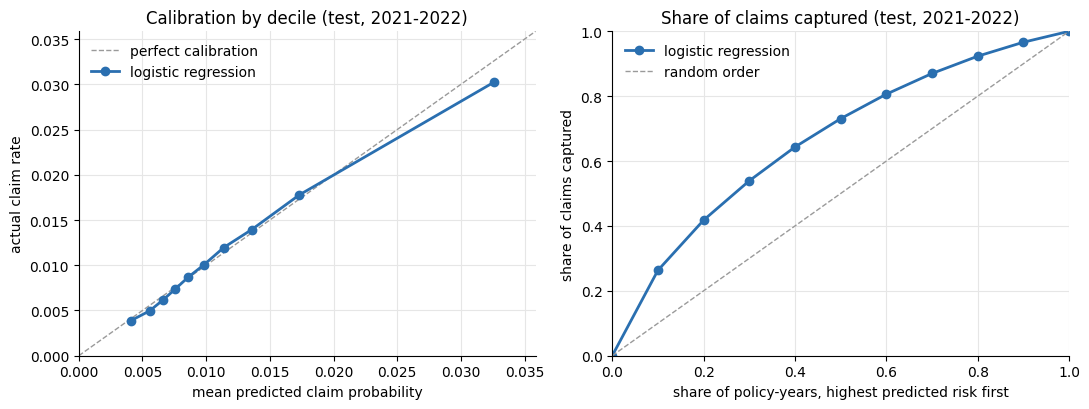

,rows,claims,predicted,actual,share_of_claims,cumulative_share_of_claims,lift
decile,,,,,,,
10,"727,572","22,002",3.260%,3.024%,26.3%,26.3%,2.63
9,"727,572","12,933",1.731%,1.778%,15.5%,41.8%,1.55
8,"727,571","10,147",1.358%,1.395%,12.1%,53.9%,1.21
7,"727,572","8,703",1.138%,1.196%,10.4%,64.3%,1.04
6,"727,571","7,305",0.982%,1.004%,8.7%,73.1%,0.87
5,"727,572","6,315",0.859%,0.868%,7.6%,80.6%,0.76
4,"727,572","5,333",0.754%,0.733%,6.4%,87.0%,0.64
3,"727,571","4,453",0.657%,0.612%,5.3%,92.3%,0.53
2,"727,572","3,600",0.555%,0.495%,4.3%,96.6%,0.43


In [10]:
# Step 5.3 Calibration and lift by decile of the predicted probability (test, 2021-2022)
pred["decile"] = pd.qcut(pred["p_logreg"].rank(method="first"), 10, labels=range(1, 11)).astype(int)  # 10 = highest risk
deciles = (pred.groupby("decile")
               .agg(rows=("y", "size"), claims=("y", "sum"), predicted=("p_logreg", "mean"), actual=("y", "mean"))
               .sort_index(ascending=False))
deciles["share_of_claims"] = deciles["claims"] / deciles["claims"].sum()
deciles["cumulative_share_of_claims"] = deciles["share_of_claims"].cumsum()
deciles["lift"] = deciles["actual"] / pred["y"].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
lim = max(deciles["predicted"].max(), deciles["actual"].max()) * 1.1
ax1.plot([0, lim], [0, lim], color="#9a9a9a", linewidth=1, linestyle="--", label="perfect calibration")
ax1.plot(deciles["predicted"], deciles["actual"], color="#2a6fb0", linewidth=2, marker="o", markersize=6, label="logistic regression")
ax1.set(title="Calibration by decile (test, 2021-2022)", xlabel="mean predicted claim probability",
        ylabel="actual claim rate", xlim=(0, lim), ylim=(0, lim))
ax1.legend(frameon=False)
share_policies = np.arange(0, 11) / 10
ax2.plot(share_policies, np.r_[0, deciles["cumulative_share_of_claims"]], color="#2a6fb0", linewidth=2, marker="o",
         markersize=6, label="logistic regression")
ax2.plot([0, 1], [0, 1], color="#9a9a9a", linewidth=1, linestyle="--", label="random order")
ax2.set(title="Share of claims captured (test, 2021-2022)", xlabel="share of policy-years, highest predicted risk first",
        ylabel="share of claims captured", xlim=(0, 1), ylim=(0, 1))
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6")
plt.tight_layout()
plt.savefig(REPORTS / "fig_claim_baseline_calibration_lift.png", dpi=150)
plt.show()
deciles.style.format({"rows": "{:,}", "claims": "{:,}", "predicted": "{:.3%}", "actual": "{:.3%}",
                      "share_of_claims": "{:.1%}", "cumulative_share_of_claims": "{:.1%}", "lift": "{:.2f}"})

#### 5.4 Confusion matrices
A confusion matrix needs a cut-off. With about 1% claims, the usual 0.5 flags almost nobody, so accuracy would be about 99% while catching no claims. We flag the **riskiest 5%, 10% and 20%** of policy-years, using cut-offs learned on the training split, and show the default 0.5 for comparison. Precision, recall and lift at each rule are the business view; PR-AUC, ROC-AUC and Brier remain our main metrics.

In [11]:
# Step 5.4 Confusion matrices at alert thresholds chosen on the TRAINING split
# The model gives a probability; a confusion matrix needs a cut-off. With 1.1% claims, the usual 0.5 flags almost
# nobody, so "accuracy" would be about 99% while catching no claims. We instead flag the riskiest 5%, 10% and 20%
# of policy-years, with the cut-off taken from training predictions (never from the test outcomes).
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

X_s, _, _ = load_rows("train", sample_rows=1_000_000)
p_train = model.predict_proba(preprocess.transform(X_s))[:, 1]
del X_s

rows = []
for flag_share in [0.05, 0.10, 0.20, None]:
    cut = 0.5 if flag_share is None else float(np.quantile(p_train, 1 - flag_share))
    flagged = (pred["p_logreg"] >= cut).astype(int)
    tn, fp, fn, tp = confusion_matrix(pred["y"], flagged, labels=[0, 1]).ravel()
    rows.append({"rule": "p >= 0.5 (default)" if flag_share is None else f"riskiest {flag_share:.0%} in train",
                 "threshold": cut, "flagged_share": flagged.mean(), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "accuracy": (tp + tn) / len(flagged),
                 "precision": precision_score(pred["y"], flagged, zero_division=0),
                 "recall": recall_score(pred["y"], flagged, zero_division=0),
                 "f1": f1_score(pred["y"], flagged, zero_division=0)})
cm_table = pd.DataFrame(rows)
cm_table["lift"] = cm_table["precision"] / pred["y"].mean()

# The 10% rule as a 2 x 2 table
r = cm_table.iloc[1]
cm10 = pd.DataFrame([[r["TN"], r["FP"]], [r["FN"], r["TP"]]],
                    index=["actual: no claim", "actual: claim"], columns=["flagged: no", "flagged: yes"])
display(cm10.style.format("{:,}"))
cm_table.style.format({"threshold": "{:.4f}", "flagged_share": "{:.1%}", "TP": "{:,}", "FP": "{:,}", "FN": "{:,}",
                       "TN": "{:,}", "accuracy": "{:.3f}", "precision": "{:.3%}", "recall": "{:.1%}",
                       "f1": "{:.3f}", "lift": "{:.2f}"})

,flagged: no,flagged: yes
actual: no claim,"6,782,319","409,795"
actual: claim,"68,575","15,028"


,rule,threshold,flagged_share,TP,FP,FN,TN,accuracy,precision,recall,f1,lift
0,riskiest 5% in train,0.0345,2.7%,"8,099","188,201","75,504","7,003,913",0.964,4.126%,9.7%,0.058,3.59
1,riskiest 10% in train,0.0254,5.8%,"15,028","409,795","68,575","6,782,319",0.934,3.537%,18.0%,0.059,3.08
2,riskiest 20% in train,0.0179,13.5%,"27,009","956,539","56,594","6,235,575",0.861,2.746%,32.3%,0.051,2.39
3,p >= 0.5 (default),0.5000,0.0%,0,0,"83,603","7,192,114",0.989,0.000%,0.0%,0.000,0.00


### Section 6. Coefficient interpretation

#### 6.1 Main coefficients
List the strongest positive and negative effects as odds ratios and check that the signs make sense (e.g. V zones raise claim risk).

intercept -0.024 (base odds 0.9763); 161 model columns


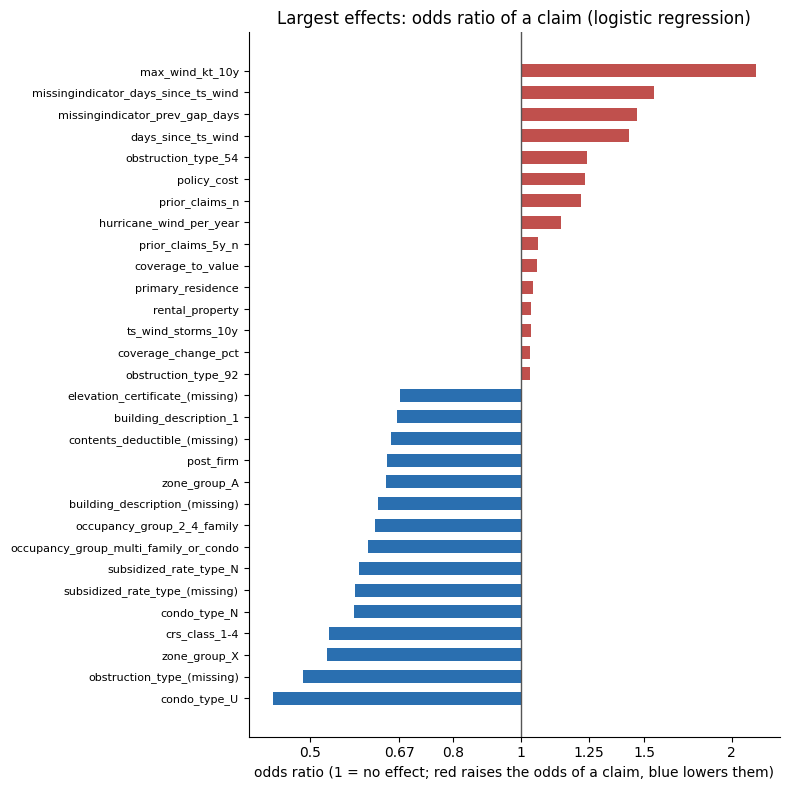

,model_column,feature,kind,coef,odds_ratio
0,max_wind_kt_10y,max_wind_kt_10y,number / flag,0.772,2.165
1,missingindicator_days_since_ts_wind,days_since_ts_wind,missing flag,0.438,1.549
2,missingindicator_prev_gap_days,prev_gap_days,missing flag,0.381,1.463
3,days_since_ts_wind,days_since_ts_wind,number / flag,0.354,1.425
4,obstruction_type_54,obstruction_type,category level,0.216,1.241
5,policy_cost,policy_cost,number / flag,0.21,1.233
6,prior_claims_n,prior_claims_n,number / flag,0.196,1.216
7,hurricane_wind_per_year,hurricane_wind_per_year,number / flag,0.13,1.139
8,prior_claims_5y_n,prior_claims_5y_n,number / flag,0.057,1.059
9,coverage_to_value,coverage_to_value,number / flag,0.051,1.052


In [12]:
# Step 6.1 Coefficients as odds ratios
# Numbers are standardized, so an odds ratio is the change in the odds of a claim for +1 standard deviation.
# Categories are one-hot with no level dropped, so compare levels within a feature (e.g. zone V vs zone X).
names = preprocess.get_feature_names_out()

def source_feature(col):
    '''The feature a model column comes from (one-hot level, missing flag or the feature itself).'''
    col = col.removeprefix("missingindicator_")
    return max((f for f in FEATS if col == f or col.startswith(f + "_")), key=len, default=col)

coefs = pd.DataFrame({"model_column": names, "coef": model.coef_.ravel()})
coefs["feature"] = coefs["model_column"].map(source_feature)
coefs["kind"] = np.select([coefs["model_column"].str.startswith("missingindicator_"),
                           coefs["feature"].isin(CATS)], ["missing flag", "category level"], "number / flag")
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs = coefs.sort_values("coef", ascending=False).reset_index(drop=True)
print(f"intercept {model.intercept_[0]:.3f} (base odds {np.exp(model.intercept_[0]):.4f}); {len(coefs)} model columns")

top = pd.concat([coefs.head(15), coefs.tail(15)])
fig, ax = plt.subplots(figsize=(8, 8))
colors = np.where(top["coef"] > 0, "#c0504d", "#2a6fb0")        # red: raises the odds of a claim; blue: lowers them
ax.barh(top["model_column"][::-1], top["odds_ratio"][::-1] - 1, left=1, color=colors[::-1], height=0.6)
ax.axvline(1, color="#555555", linewidth=1)
ax.set(title="Largest effects: odds ratio of a claim (logistic regression)",
       xlabel="odds ratio (1 = no effect; red raises the odds of a claim, blue lowers them)")
ax.set_xscale("log")
lo, hi = top["odds_ratio"].min(), top["odds_ratio"].max()
ticks = [t for t in (0.25, 0.33, 0.5, 0.67, 0.8, 1, 1.25, 1.5, 2, 3, 4) if lo / 1.1 <= t <= hi * 1.1]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.tick_params(axis="y", labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS / "fig_claim_baseline_odds_ratios.png", dpi=150)
plt.show()
top[["model_column", "feature", "kind", "coef", "odds_ratio"]].round(3)

### Section 7. Save

#### 7.1 Save the model and results
We save the fitted model to `data/processed/models/`, the test predictions to `data/processed/predictions/`, and the metrics, deciles, confusion matrices, coefficients and run record to `reports/`. The last line reloads the saved model and checks it gives the same predictions.

In [13]:
# Step 7.1 Save the model, the test predictions and the results
import json
import joblib
from datetime import datetime
from src.modeling import make_portable

MODEL_DIR = PROCESSED / "models"
PRED_DIR = PROCESSED / "predictions"
for d in (MODEL_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)
NAME = "claim_baseline_logreg"

# The model: preprocessing + logistic regression, with any notebook-defined clipper swapped for src.modeling's
print("clippers made portable:", make_portable(preprocess))
joblib.dump({"preprocess": preprocess, "model": model, "features": FEATS}, MODEL_DIR / f"{NAME}.joblib")

# Test predictions, row by row, so notebook 08 can compare models without retraining
pred[["period_id", "period_year", "y", "p_logreg", "p_segment", "p_base"]].to_parquet(
    PRED_DIR / f"{NAME}_test.parquet", index=False)

# Results tables
results.to_csv(REPORTS / f"{NAME}_test_metrics.csv", index=False)
deciles.to_csv(REPORTS / f"{NAME}_test_deciles.csv")
coefs.to_csv(REPORTS / f"{NAME}_coefficients.csv", index=False)
cm_table.to_csv(REPORTS / f"{NAME}_test_confusion.csv", index=False)
segment_rates.to_csv(REPORTS / "claim_benchmark_segment_rates.csv", index=False)

# Run record: what was trained, on what, with which settings
run = {
    "model": NAME, "target": TARGET, "saved_at": datetime.now().isoformat(timespec="seconds"),
    "train_split": "train (2014-2020), every row, in chunks", "scored_on": "test (2021-2022)",
    "features_used": FEATS, "features_excluded": list(EXCLUDE),
    "model_columns": int(len(preprocess.get_feature_names_out())),
    "params": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
               for k, v in model.get_params().items()},
    "epochs": N_EPOCHS, "chunks": N_CHUNKS, "seed": SEED, "base_rate_train": base_rate,
    "test_overall": results.query("scope == '2021-2022' and model == 'logistic regression'").iloc[0].drop(["scope", "model"]).to_dict(),
}
(REPORTS / f"{NAME}_run.json").write_text(json.dumps(run, indent=2, default=float))

# Check: the saved model loads and gives the same predictions
saved = joblib.load(MODEL_DIR / f"{NAME}.joblib")
X_check, _, _ = load_rows("test", sample_rows=1000)
same = np.allclose(saved["model"].predict_proba(saved["preprocess"].transform(X_check))[:, 1],
                   model.predict_proba(preprocess.transform(X_check))[:, 1])
print(f"saved {NAME}.joblib, {NAME}_test.parquet, metrics, deciles, coefficients and run record; reload gives the same predictions: {same}")

clippers made portable: 0
saved claim_baseline_logreg.joblib, claim_baseline_logreg_test.parquet, metrics, deciles, coefficients and run record; reload gives the same predictions: True
